# [실습] 비텍스트 RAG — 표 청킹 · 검색분리 · 멀티모달 (셀 5~12)

| 단계 | 셀 | 내용 |
|------|----|------|
| 0️⃣ 준비 | 준비 셀 | 샘플 PDF 생성 + 단순/구조보존 추출 (셀 1~4 결과 재현) |
| 3️⃣ 응용 | 5~6 | ① 작은 표 1청크 ② 큰 표 머리글 복제 |
| 4️⃣ 데이터 활용 | 7~9 | 검색/원본 분리 · 단순 vs 구조보존 비교 · 검수 |
| 5️⃣ 멀티모달 | 10~12 | PDF 페이지 이미지 캡처 · 비전 OCR · 텍스트 vs 멀티모달 비교 |

### ✍️ 실습 방법
- 코드 속 `____` (밑줄 4개)를 알맞은 코드로 채운 뒤 실행하세요.
- `# TODO` 주석이 채울 곳을 설명합니다. 막히면 **💡 힌트**를 펼쳐 보세요.
- 각 셀 아래 **✅ 기대 출력**과 내 결과를 비교하세요.
- **준비 셀부터 위에서 순서대로** 실행해야 합니다.
- 셀 11은 **OpenAI API 키**가 필요합니다 (Colab 비밀키 또는 환경변수 `OPENAI_API_KEY`).

# 0️⃣ 준비 — 셀 1~4 결과 재현 (그대로 실행)

셀 5부터 쓰는 변수 `raw_text`(단순 추출), `extracted_table`(구조 보존 추출)과
파일 `sample_report.pdf` 를 만듭니다. **빈칸 없이 그대로 실행**하세요.

In [ ]:
!pip install -q reportlab pypdf pdfplumber langchain_openai

In [1]:
# ── 샘플 PDF 생성 (셀 2) ──────────────────────────────────
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Table, TableStyle, Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.cidfonts import UnicodeCIDFont

table_data = [
    ["구분", "매출", "증감"],
    ["국내", "120억", "+8%"],
    ["해외", "85억",  "-3%"],
    ["온라인", "47억", "+15%"],
]

FONT = "HYSMyeongJo-Medium"
pdfmetrics.registerFont(UnicodeCIDFont(FONT))
styles = getSampleStyleSheet()
for name in ("Title", "Normal"):
    styles[name].fontName = FONT

pdf_table = Table(table_data)
pdf_table.setStyle(TableStyle([
    ("GRID", (0, 0), (-1, -1), 0.5, colors.black),
    ("FONTNAME", (0, 0), (-1, -1), FONT),
]))
SimpleDocTemplate("sample_report.pdf", pagesize=A4).build([
    Paragraph("2026년 1분기 실적 보고", styles["Title"]),
    Spacer(1, 12),
    Paragraph("[표 1] 부문별 매출 현황", styles["Normal"]),
    Spacer(1, 6),
    pdf_table,
])

# ── 단순 추출 (셀 3) ─────────────────────────────────────
import pypdf
raw_text = pypdf.PdfReader("sample_report.pdf").pages[0].extract_text()

# ── 구조 보존 추출 (셀 4) ─────────────────────────────────
import pdfplumber
with pdfplumber.open("sample_report.pdf") as pdf:
    extracted_table = pdf.pages[0].extract_tables()[0]

print("✅ 준비 완료")
print("raw_text 앞부분 :", " ".join(raw_text.split())[:40], "...")
print("extracted_table :", extracted_table)

✅ 준비 완료
raw_text 앞부분 : 2026년 1분기 실적 보고 [표 1] 부문별 매출 현황 구분 매출 증감 ...
extracted_table : [['구분', '매출', '증감'], ['국내', '120억', '+8%'], ['해외', '85억', '-3%'], ['온라인', '47억', '+15%']]


**✅ 기대 출력**
```
✅ 준비 완료
raw_text 앞부분 : 2026년 1분기 실적 보고 [표 1] 부문별 매출 현황 구분 ...
extracted_table : [['구분', '매출', '증감'], ['국내', '120억', '+8%'], ...]
```

# 3️⃣ 단계 — 표를 RAG에 담는 형태로 만들기

## ① 작은 표 → 마크다운 1청크

### 셀 5 — 표를 마크다운으로 변환 (LLM이 잘 읽는 형식)

작은 표(~20행)는 **표 1개 = 1청크**. 행 도중에 쪼개지 않습니다.
+ **캡션을 맥락 한 줄로** 붙여 "무엇에 대한 표인지" 알 수 있게 합니다.

**TODO**
1. `table_to_markdown()` 의 구분선(`| --- | --- | --- |`)과 본문 행을 완성하세요.
2. 캡션과 마크다운 표를 **줄바꿈**으로 이어 `table_chunk` 를 만드세요.

<details><summary>💡 힌트</summary>

- 열 개수만큼 `"---"` 반복: `["---"] * len(rows[0])`
- 본문: 머리글 다음 행부터 → `rows[1:]`, 각 행은 머리글과 같은 방식으로 `" | ".join(r)`
- 줄바꿈 연결: `caption + "\n" + ...`
</details>

In [2]:
def table_to_markdown(rows):
    header  = "| " + " | ".join(rows[0]) + " |"
    # TODO 1-a: 열 개수만큼 '---' 를 넣은 구분선
    divider = "| " + " | ".join(["---"] * len(rows[0])) + " |"
    # TODO 1-b: 머리글을 제외한 나머지 행들을 마크다운 행으로
    body    = ["| " + " | ".join(r) + " |" for r in rows[1:]]
    return "\n".join([header, divider] + body)

caption = "[표 1] 2026년 1분기 부문별 매출 현황"

# TODO 2: 캡션 + 줄바꿈 + 마크다운 표
table_chunk = caption + "\n" + table_to_markdown(extracted_table)
print(table_chunk)

[표 1] 2026년 1분기 부문별 매출 현황
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 국내 | 120억 | +8% |
| 해외 | 85억 | -3% |
| 온라인 | 47억 | +15% |


**✅ 기대 출력**
```
[표 1] 2026년 1분기 부문별 매출 현황
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 국내 | 120억 | +8% |
| 해외 | 85억 | -3% |
| 온라인 | 47억 | +15% |
```
> 💡 마크다운 표는 한 행이 한 줄에 완결돼 LLM이 행·열 관계를 정확히 읽습니다.

## ② 큰 표 → 머리글 복제하며 분할

### 셀 6 — 큰 표는 조각마다 머리글 복제

100행짜리 큰 표는 통째 1청크 불가. 행 그룹으로 나누되 —
**매 조각에 머리글 행을 복제**해 붙여야 열 의미가 살아남습니다.

**TODO**
1. `big_table` 을 머리글(`header`)과 나머지 행(`rows`)으로 나누세요.
2. `chunk_size` 행씩 잘라 낸 `block` 앞에 **머리글을 붙이세요.**

<details><summary>💡 힌트</summary>

- 첫 행: `big_table[0]`, 나머지: `big_table[1:]`
- `range(시작, 끝, 간격)` 으로 `chunk_size` 씩 건너뛰기
- 머리글 복제: `[header] + block`
</details>

In [3]:
big_table = [
    ["구분", "매출", "증감"],
    ["국내", "120억", "+8%"], ["해외", "85억", "-3%"],
    ["온라인", "47억", "+15%"], ["오프라인", "73억", "-1%"],
    ["B2B", "210억", "+22%"], ["B2C", "88억", "+5%"],
]

# TODO 1: 머리글 / 나머지 행 분리
header, rows = big_table[0], big_table[1:]

chunk_size = 2
chunks = []
for i in range(0, len(rows), chunk_size):
    block = rows[i:i + chunk_size]
    # TODO 2: 머리글 복제 + 현재 블록
    chunk = [header] + block
    chunks.append(table_to_markdown(chunk))

for n, chunk in enumerate(chunks, 1):
    print(f"───── 조각 {n} ─────")
    print(chunk, "\n")

───── 조각 1 ─────
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 국내 | 120억 | +8% |
| 해외 | 85억 | -3% | 

───── 조각 2 ─────
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 온라인 | 47억 | +15% |
| 오프라인 | 73억 | -1% | 

───── 조각 3 ─────
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| B2B | 210억 | +22% |
| B2C | 88억 | +5% | 



**✅ 기대 출력**: 조각 3개, **모든 조각의 첫 줄이** `| 구분 | 매출 | 증감 |`
```
───── 조각 1 ─────
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 국내 | 120억 | +8% |
| 해외 | 85억 | -3% |
...
```
> 💡 큰 표에서 가장 흔한 실수인 **머리글 분실**을 막는 규칙입니다.

# 4️⃣ 단계 — 검색/원본 분리 · 비교 · 검수

### 셀 7 — 검색용 요약 / 답변용 원본 분리

표를 마크다운 그대로 임베딩하면 기호·숫자가 많아 의미 매칭이 약합니다.
그래서 **검색은 '요약'으로, 답변은 '원본'으로** 분리합니다.

```
 색인:  표 ─▶ 요약(검색용)  ─▶ search_index
          └─▶ 원본(답변용) ─▶ docstore        같은 id 로 연결 🔑
 검색:  질문 ─▶ 요약으로 검색 ─▶ id ─▶ docstore에서 원본 꺼내 전달
```

**TODO**
1. 고유 `doc_id` 를 만드세요.
2. **같은 `doc_id`** 로 `docstore`(원본)와 `search_index`(요약)에 저장하세요.
3. 찾은 id로 `docstore` 에서 원본을 꺼내 출력하세요.

<details><summary>💡 힌트</summary>

- 고유 id: `str(uuid.uuid4())`
- 딕셔너리: `{키: 값}`
- 원본 꺼내기: `docstore[found_id]`
</details>

In [5]:
import uuid

table_original = table_chunk                                                      # 답변용 (셀 5 결과)
table_summary  = "2026년 1분기 부문별 매출과 증감률 표. 국내 해외 온라인 매출 실적"  # 검색용

# TODO 1: 고유 id
doc_id = str(uuid.uuid4())

# TODO 2: 같은 id 로 두 저장소에 저장
docstore     = {doc_id: table_original}   # 답변용 저장소 (원본)
search_index = {doc_id: table_summary}   # 검색용 저장소 (요약)

def search(query):
    # 질문 단어 중 하나라도 요약에 들어 있으면 그 id 반환 (단순 키워드 검색)
    for _id, summary in search_index.items():
        if any(word in summary for word in query.split()):
            return _id
    return None

found_id = search("해외 매출 증감 알려줘")
print("🔎 검색은 '요약'으로 → id:", found_id[:8])

# TODO 3: 찾은 id 로 원본 꺼내기
print("📦 LLM엔 '원본' 전달:\n", docstore[found_id])

🔎 검색은 '요약'으로 → id: daa65c69
📦 LLM엔 '원본' 전달:
 [표 1] 2026년 1분기 부문별 매출 현황
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 국내 | 120억 | +8% |
| 해외 | 85억 | -3% |
| 온라인 | 47억 | +15% |


**✅ 기대 출력**: id 앞 8자리(실행마다 다름) + 셀 5의 마크다운 표 원본

> 💡 그림·차트도 똑같습니다: **그림 → 요약 텍스트(검색용) + 원본 그림(답변용)**.

### 셀 8 — 단순 vs 구조보존, 같은 질문에 답 비교 (핵심!)

같은 질문을 **단순 추출본**과 **구조 보존본**에 던져 답이 어떻게 갈리는지 봅니다.
(LLM 없이, 규칙 기반으로 차이만 드러냄)

**TODO**: `answer_from_struct()` 에서
1. 표의 첫 행을 머리글(`head`)로 잡고,
2. 머리글을 제외한 행을 돌며 **첫 열(구분)에 키워드가 있는 행**을 찾고,
3. `머리글: 값` 쌍으로 묶어 반환하세요.

<details><summary>💡 힌트</summary>

- 머리글: `extracted_table[0]` / 데이터 행: `extracted_table[1:]`
- 첫 열: `row[0]`
- 짝 맞추기: `zip(head, row)`
</details>

In [10]:
def answer_from_plain(query):
    # 단순 추출본(1차원 텍스트)에서 질문 첫 단어 주변 30글자를 긁어옴
    key = query.split()[0]
    flat = " ".join(raw_text.split())
    idx = flat.find(key)
    return flat[idx:idx + 30] + " ..." if idx >= 0 else "(못 찾음)"

def answer_from_struct(query):
    # 구조 보존본(2차원 표)에서 해당 '행'을 정확히 찾음
    key = query.split()[0]
    # TODO 1: 머리글 행
    head = extracted_table[0]
    # TODO 2: 데이터 행 순회
    for row in extracted_table[1:]:
        if key in row[0]:
            # TODO 3: '머리글: 값' 쌍으로 연결
            return " / ".join(f"{h}: {v}" for h, v in zip(head, row))
    return "(못 찾음)"

q = "해외 매출 증감"
print(f"🧑 질문: {q}\n")
print("─── 단순 추출 답 ───")
print(answer_from_plain(q))
print("\n─── 구조 보존 답 ───")
print(answer_from_struct(q))

🧑 질문: 해외 매출 증감

─── 단순 추출 답 ───
해외 85억 -3% 온라인 47억 +15% ...

─── 구조 보존 답 ───
구분: 해외 / 매출: 85억 / 증감: -3%


**✅ 기대 출력**
```
─── 단순 추출 답 ───
해외 85억 -3% 온라인 47억 +15% ...

─── 구조 보존 답 ───
구분: 해외 / 매출: 85억 / 증감: -3%
```
> ✅ **같은 문서인데 추출 방식만 달라** 답 품질이 갈립니다.

### 셀 9 — 추출 결과 검수

추출은 한 번에 완벽하지 않습니다. **병합 셀**은 빈칸/`None`으로 깨지기 쉬우니,
추출 직후 빈 셀이 있는지 점검하는 습관을 들입니다.

**TODO**: 모든 셀을 돌며 값이 `None` 이거나 빈 문자열 `""` 인 셀의 `(행, 열)` 위치를 `bad` 에 모으세요.

<details><summary>💡 힌트</summary>

- 이중 반복 리스트 컴프리헨션: `[(r, c) for r, row in enumerate(rows) for c, cell in enumerate(row) if 조건]`
- 조건: `cell in (None, "")`
</details>

In [11]:
def validate_table(rows):
    # TODO: 빈/None 셀의 (행, 열) 좌표 목록
    bad = [(r, c) for r, row in enumerate(rows) for c, cell in enumerate(row) if cell in (None, "")]
    return "⚠️ 빈/병합 의심 셀: " + str(bad) if bad else "✅ 이상 없음"

print(validate_table(extracted_table))                 # 정상 표
print(validate_table([["연도", None, None],             # 병합 흉내 표
                       ["2026", "120억", "+8%"]]))

✅ 이상 없음
⚠️ 빈/병합 의심 셀: [(0, 1), (0, 2)]


**✅ 기대 출력**
```
✅ 이상 없음
⚠️ 빈/병합 의심 셀: [(0, 1), (0, 2)]
```
> 💡 **"추출하면 끝"이 아니라 "추출 → 검수"** 가 기초 습관입니다.

# 5️⃣ 단계 — 멀티모달: PDF를 '이미지로' 받아들이기

> 지금까지(2~4단계): `pdfplumber`로 표를 **텍스트로** 추출했습니다.
> 그런데 현실의 많은 PDF는 표·차트가 **이미지로 박혀** 있어 텍스트 추출이 **0글자**입니다
> (스캔 문서, 그림 표, 도표).

```
 [텍스트 추출 가능]          [이미지로 박힌 표]
 pdfplumber → 표 살아남      pdfplumber → 0글자 ❌
        │                          │
        ▼                          ▼ 멀티모달
 4단계까지로 충분            페이지를 이미지로 캡처
                            → 비전 모델이 표를 OCR ✅
```

**핵심 발상**: 텍스트 추출이 안 되면, **PDF 페이지를 그림으로 캡처해
비전 모델(gpt-4o)에게 "이 표를 글자로 옮겨줘"** 라고 시킵니다.

### 셀 10 — PDF 페이지를 이미지로 캡처

`pdfplumber`의 `to_image()`로 페이지를 통째로 그림으로 만듭니다.
해상도는 300dpi (표 글자가 또렷해야 비전이 잘 읽음).

**TODO**
1. 해상도 `DPI` 를 **300** 으로 지정하세요.
2. 첫 페이지를 `DPI` 해상도의 이미지로 만들어 `page_image.png` 로 저장하세요.
3. 저장한 이미지를 PIL로 열어 `img` 에 담으세요.

<details><summary>💡 힌트</summary>

- 페이지 → 이미지: `page.to_image(resolution=DPI)` → `.save("파일명")`
- 이미지 열기: `Image.open("파일명")`
- `except` 블록(우회 경로)은 Pillow 설치가 꼬였을 때만 쓰이므로 그대로 두세요.
</details>

캡처 방식: pdfplumber
✅ PDF 1페이지를 이미지로 캡처: (2481, 3508) px


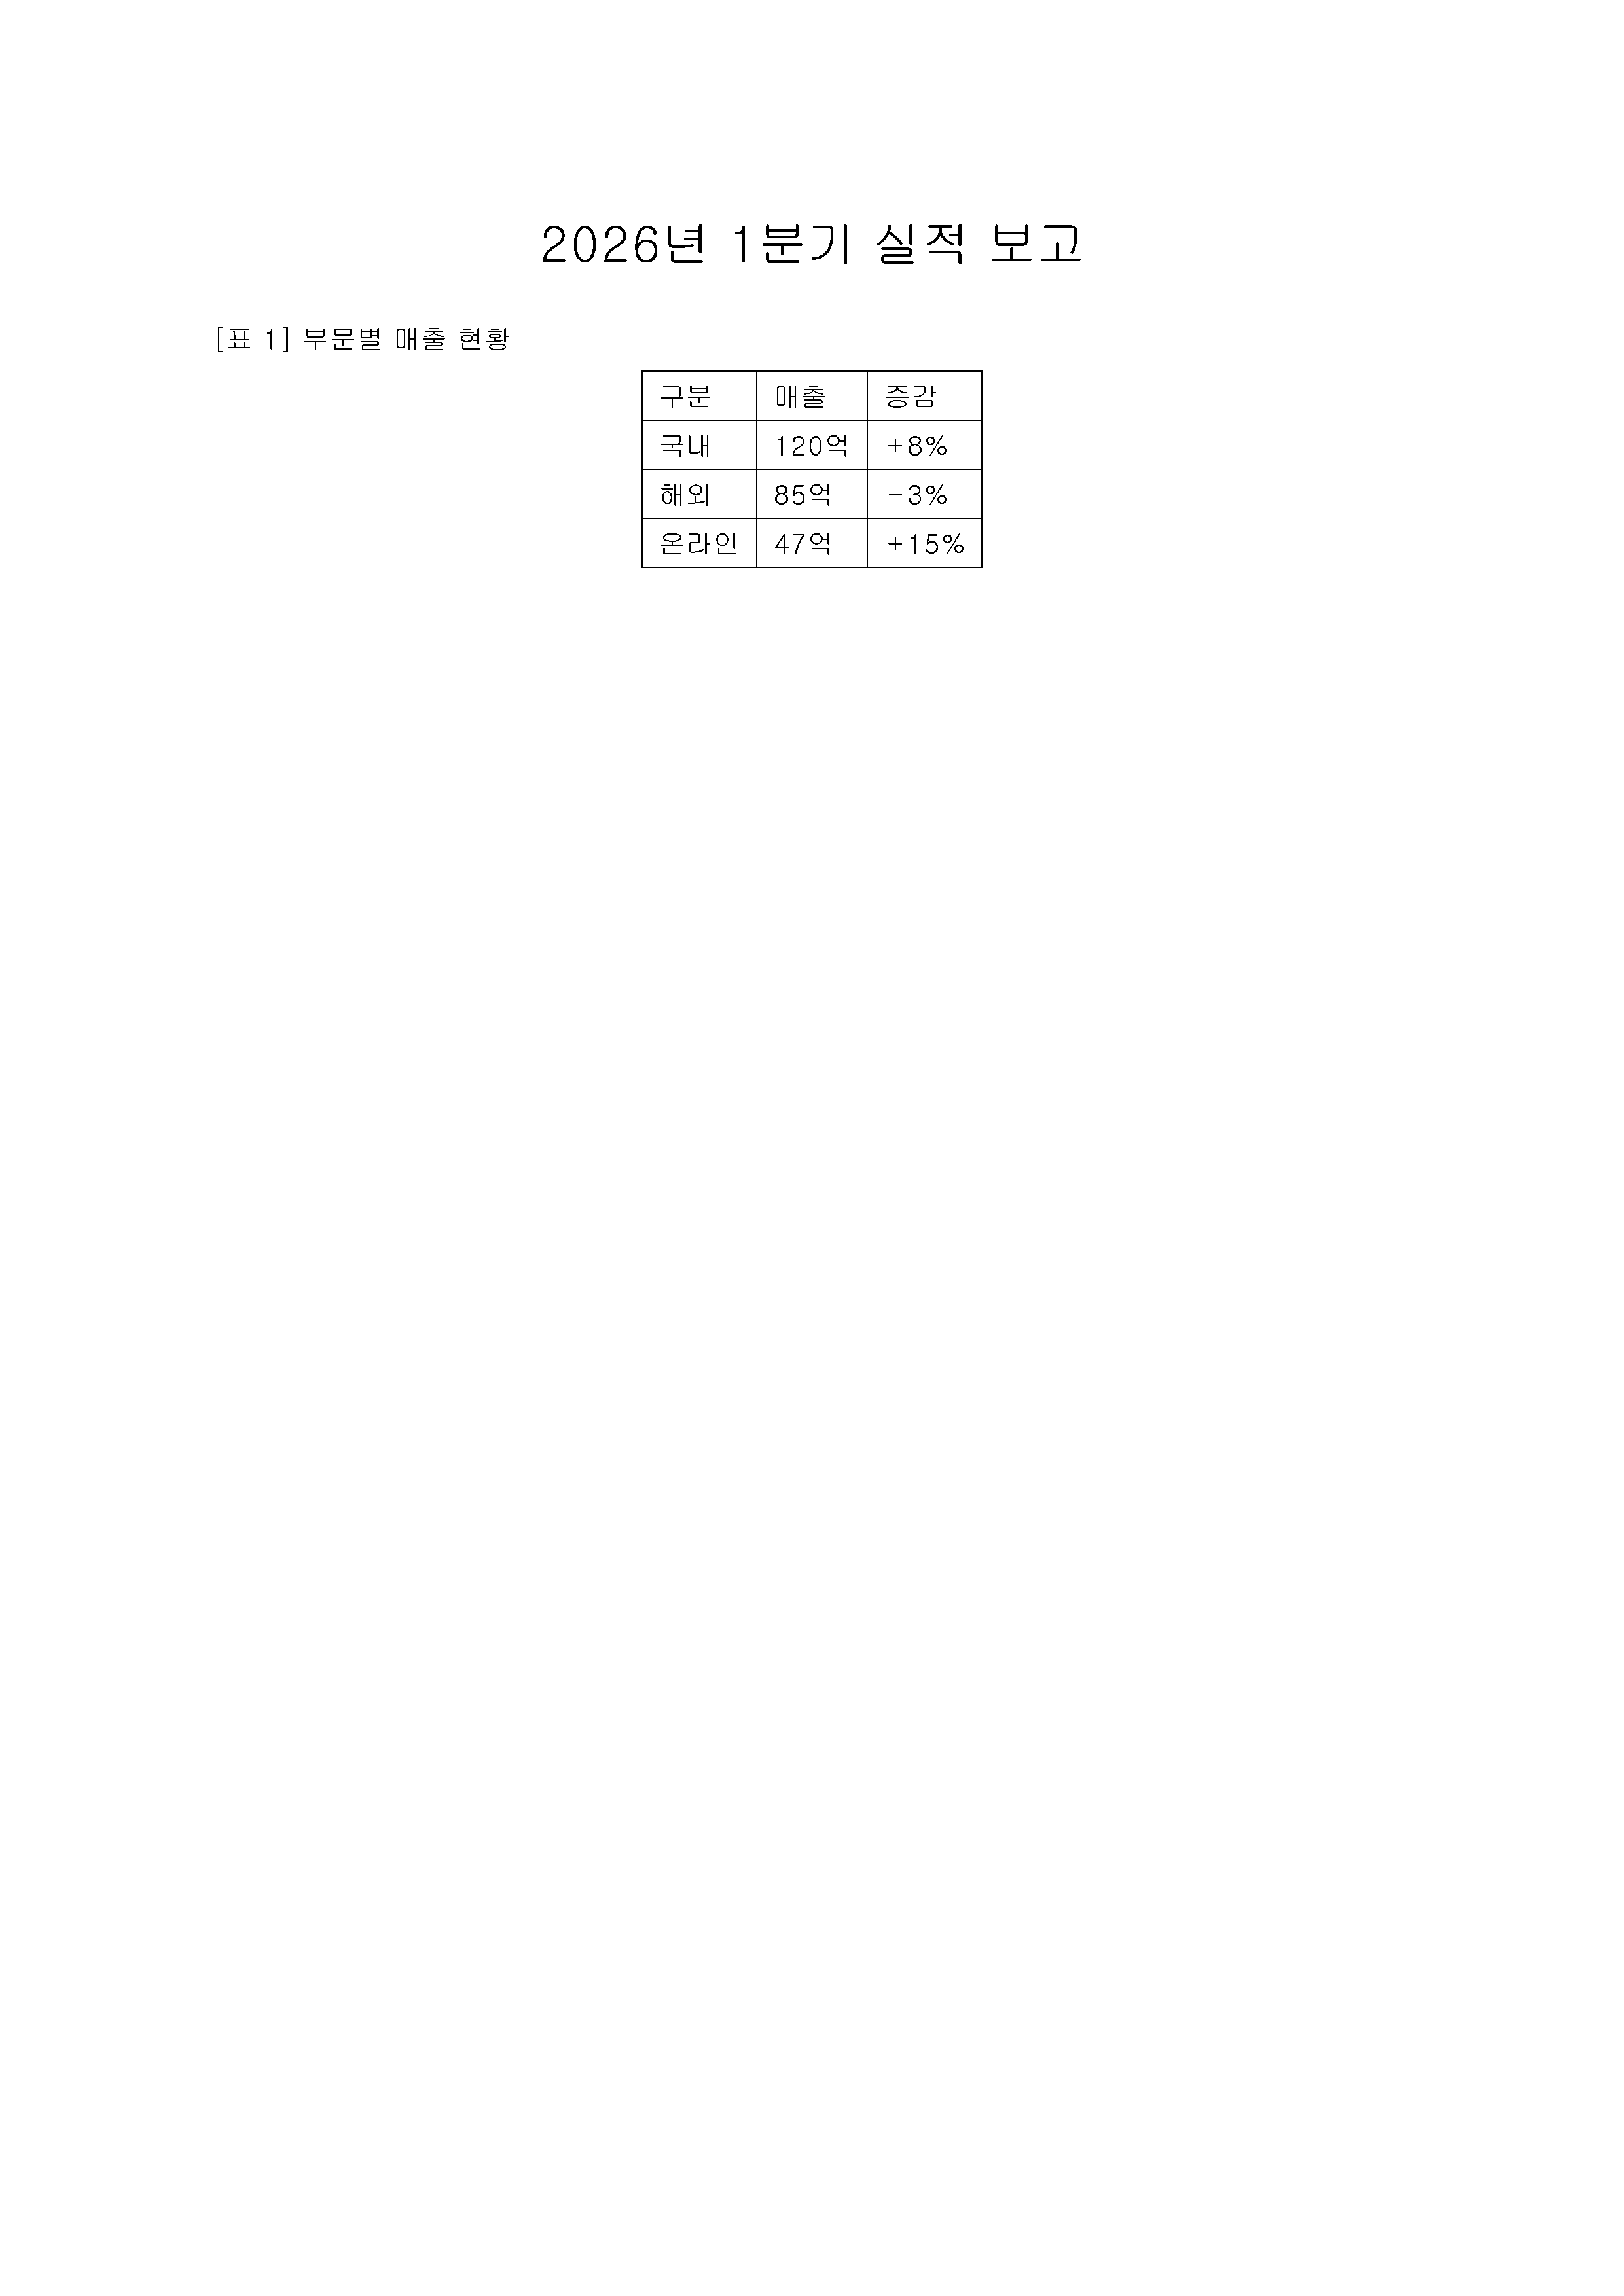

In [13]:
import os

PDF = "content/sample_report.pdf" if os.path.exists("content/sample_report.pdf") \
      else "sample_report.pdf"

# TODO 1: 해상도 (표의 작은 숫자도 또렷하게)
DPI = 300

try:
    import pdfplumber
    with pdfplumber.open(PDF) as pdf:
        # TODO 2: 첫 페이지 → DPI 해상도 이미지 → page_image.png 저장
        pdf.pages[0].to_image(resolution=DPI).save("content/page_image.png")
    print("캡처 방식: pdfplumber")

except ImportError as e:
    # Pillow가 꼬인 환경('_Ink' ImportError) 우회: pypdfium2로 직접 렌더 (그대로 두세요)
    import pypdfium2 as pdfium
    doc = pdfium.PdfDocument(PDF)
    doc[0].render(scale=DPI / 72).to_pil().save("content/page_image.png")
    print(f"캡처 방식: pypdfium2 (pdfplumber 우회 — {e})")

from PIL import Image
# TODO 3: 저장한 이미지 열기
img = Image.open("content/page_image.png")
print(f"✅ PDF 1페이지를 이미지로 캡처: {img.size} px")
img

**✅ 기대 출력**: `✅ PDF 1페이지를 이미지로 캡처: (2481, 3508) px` 와 페이지 이미지

> 💡 A4(595×842pt) × 300/72 ≈ 2481×3508px. DPI를 72로 바꾸면 크기가 어떻게 달라질까요?

### 셀 11 — 비전 모델로 표 복원 (OCR)

GPT-4o 비전이 이미지 속 표를 마크다운으로 옮깁니다.

> ⚠️ **주의점**: 프롬프트에 도메인 단어(세금·매출·실적 등)가 많으면 비전 모델이
> *자문 요청*으로 오인해 "I can't assist"로 거부할 수 있습니다.
> 그래서 **"표를 그대로 옮기는 OCR 작업"** 임을 명확히 합니다.

**TODO**
1. 이미지 파일을 **base64 문자열**로 인코딩하세요.
2. 비전 모델 `gpt-4o`, `temperature=0` 으로 생성하세요.
3. 이미지 URL을 `data:image/png;base64,...` 형식으로 넣으세요.
4. 모델을 호출해 응답 **텍스트**를 꺼내세요.

<details><summary>💡 힌트</summary>

- 인코딩: `base64.b64encode(바이트).decode()`
- 모델: `ChatOpenAI(model="gpt-4o", temperature=0)`
- 데이터 URL: `f"data:image/png;base64,{img_b64}"`
- 호출 결과 텍스트: `vision.invoke([ocr_msg]).content`
</details>

In [17]:
import os, base64
# OpenAI 키 (Colab 비밀키 또는 환경변수)
try:
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
except Exception:
    pass  # 이미 환경변수에 있으면 그대로 사용

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

with open("content/page_image.png", "rb") as f:
    # TODO 1: 이미지 바이트 → base64 문자열
    img_b64 = base64.b64encode(f.read()).decode()

# TODO 2: 비전 가능 모델 (표 정확도 위해 mini 아닌 gpt-4o, 결과 고정 위해 temperature 0)
vision = ChatOpenAI(model="gpt-4o", temperature=0)

# 프롬프트 핵심: '분석/요약'이 아니라 '전사(OCR)'
ocr_msg = HumanMessage(content=[
    {"type": "text", "text":
     "다음 이미지에 표가 있습니다. OCR 작업입니다: 표의 "
     "각 행과 열에 적힌 글자·숫자를 보이는 그대로 마크다운 "
     "표로 옮기세요. 해석·요약하지 말고 그대로 전사만 하세요."},
    {"type": "image_url",
     # TODO 3: base64 데이터 URL
     "image_url": {"url": f"data:image/png;base64, {img_b64}",
                   "detail": "high"}},
])

# TODO 4: 모델 호출 → 응답 텍스트
vision_table = vision.invoke([ocr_msg]).content

print("─── 비전 복원 결과 ───")
print(vision_table)
if "sorry" in vision_table.lower() or "can't" in vision_table.lower():
    print("\n⚠️ 비전 복원 실패. 셀 재실행 또는 키 권한 확인.")
else:
    print("\n✅ 이미지 표 → 텍스트 복원 성공")

─── 비전 복원 결과 ───
```markdown
| 구분   | 매출  | 증감   |
|------|-----|------|
| 국내   | 120억 | +8%  |
| 해외   | 85억  | -3%  |
| 온라인 | 47억  | +15% |
```

✅ 이미지 표 → 텍스트 복원 성공


**✅ 기대 출력** (공백·정렬은 조금 다를 수 있음)
```
| 구분   | 매출  | 증감 |
|--------|-------|------|
| 국내   | 120억 | +8%  |
| 해외   | 85억  | -3%  |
| 온라인 | 47억  | +15% |

✅ 이미지 표 → 텍스트 복원 성공
```
> 💡 텍스트 추출이 0글자였어도, 이제 검색·답변에 쓸 수 있는 텍스트가 됐습니다.

### 셀 12 — 텍스트 추출 vs 멀티모달 비교 (핵심!)

같은 PDF를 ① 단순 텍스트 추출 ② 멀티모달(비전)로 처리해 차이를 봅니다.
(이 PDF는 텍스트 추출도 되지만, **이미지로만 된 PDF라면 ①은 빈손**이라는 게 핵심)

**TODO**
1. `pypdf` 로 첫 페이지 텍스트를 추출하세요. 결과가 `None` 이면 빈 문자열로 바꾸고 앞뒤 공백을 지우세요.
2. 셀 11의 비전 복원 결과를 출력하세요.
3. 마지막 **✏️ 검수** 칸에서, 셀 9의 `validate_table()` 로 구조 보존 표를 다시 점검하세요.

<details><summary>💡 힌트</summary>

- `None` 대비: `(값 or "")` → `.strip()`
- 비전 결과 변수: `vision_table`
- 검수 함수: `validate_table(extracted_table)`
</details>

In [19]:
print("=" * 55)
print("① 단순 텍스트 추출 (pypdf)")
print("=" * 55)
import pypdf
r = pypdf.PdfReader("content/sample_report.pdf")
# TODO 1: 첫 페이지 텍스트 (None 이면 "" 로) + 앞뒤 공백 제거
plain = (None or "").strip()
print(plain if plain else "(추출 0글자 — 이미지 PDF였다면 이렇게 빈손)")

print("\n" + "=" * 55)
print("② 멀티모달 (페이지 → 이미지 → 비전 OCR)")
print("=" * 55)
# TODO 2: 비전 복원 결과 출력
print(vision_table)

print("\n" + "=" * 55)
print("✏️ 검수 (셀 9 함수 재사용)")
# TODO 3: 구조 보존 표 검수
print(validate_table(extracted_table))

① 단순 텍스트 추출 (pypdf)
(추출 0글자 — 이미지 PDF였다면 이렇게 빈손)

② 멀티모달 (페이지 → 이미지 → 비전 OCR)
```markdown
| 구분   | 매출  | 증감   |
|------|-----|------|
| 국내   | 120억 | +8%  |
| 해외   | 85억  | -3%  |
| 온라인 | 47억  | +15% |
```

✏️ 검수 (셀 9 함수 재사용)
✅ 이상 없음


**✅ 기대 출력**: ① 한 줄씩 흩어진 텍스트 / ② 마크다운 표 / `✅ 이상 없음`

| 방식 | 이미지로 박힌 표일 때 |
|------|----------------------|
| 텍스트 추출 | 0글자 — 아예 못 읽음 ❌ |
| 멀티모달(비전) | 표를 텍스트로 복원 ✅ |

> 교훈: 텍스트 추출이 실패하는 PDF(스캔·그림표·도표)는 멀티모달이 유일한 길.
> 단, 비전도 100%는 아니니 **복원 결과를 원본과 대조하는 검수가 필수**입니다.

---
# 🎓 정리

```
 PDF 받으면 먼저 판단:
   pdfplumber로 표가 텍스트로 나오나?
        │
   ├─ YES → 2~4단계 (텍스트 추출, 빠르고 저렴)
   └─ NO  → 5단계 멀티모달 (페이지 이미지 → 비전 OCR)
```

| 항목 | 텍스트 추출 | 멀티모달 |
|------|-------------|----------|
| 속도·비용 | 빠름·저렴 | 느림·LLM 비용 |
| 이미지 표 | ❌ 0글자 | ✅ 복원 |
| 정확도 | 구조 보존시 높음 | 비전 의존(검수 필수) |

| 이론 | 이 실습에서 한 일 |
|------|-------------------|
| 작은 표 청킹 | 표 1개 = 1청크 + 캡션을 맥락 한 줄로 (셀 5) |
| 큰 표 청킹 | 조각마다 머리글 행 복제 (셀 6) |
| 검색/답변 분리 | `id`로 연결, 검색=요약·전달=원본 (셀 7) |
| 추출 방식 비교 | 같은 질문, 단순 vs 구조보존 답 비교 (셀 8) |
| 추출 검수 | 빈/병합 셀 점검 (셀 9) |
| 멀티모달 | 페이지 이미지 → 비전 OCR → 표 복원 (셀 10~12) |

## 🤔 더 해보기 (선택)

1. 셀 6의 `chunk_size` 를 `3` 으로 바꾸면 조각이 어떻게 나뉘는지 확인해 보세요.

In [20]:
big_table = [
    ["구분", "매출", "증감"],
    ["국내", "120억", "+8%"], ["해외", "85억", "-3%"],
    ["온라인", "47억", "+15%"], ["오프라인", "73억", "-1%"],
    ["B2B", "210억", "+22%"], ["B2C", "88억", "+5%"],
]

# TODO 1: 머리글 / 나머지 행 분리
header, rows = big_table[0], big_table[1:]

chunk_size = 3
chunks = []
for i in range(0, len(rows), chunk_size):
    block = rows[i:i + chunk_size]
    # TODO 2: 머리글 복제 + 현재 블록
    chunk = [header] + block
    chunks.append(table_to_markdown(chunk))

for n, chunk in enumerate(chunks, 1):
    print(f"───── 조각 {n} ─────")
    print(chunk, "\n")

───── 조각 1 ─────
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 국내 | 120억 | +8% |
| 해외 | 85억 | -3% |
| 온라인 | 47억 | +15% | 

───── 조각 2 ─────
| 구분 | 매출 | 증감 |
| --- | --- | --- |
| 오프라인 | 73억 | -1% |
| B2B | 210억 | +22% |
| B2C | 88억 | +5% | 



2. 셀 8의 `q` 를 `"국내 매출 증감"` 등으로 바꿔도 구조 보존 쪽이 정확한 행을 반환하는지 살펴보세요.

In [21]:
def answer_from_plain(query):
    # 단순 추출본(1차원 텍스트)에서 질문 첫 단어 주변 30글자를 긁어옴
    key = query.split()[0]
    flat = " ".join(raw_text.split())
    idx = flat.find(key)
    return flat[idx:idx + 30] + " ..." if idx >= 0 else "(못 찾음)"

def answer_from_struct(query):
    # 구조 보존본(2차원 표)에서 해당 '행'을 정확히 찾음
    key = query.split()[0]
    # TODO 1: 머리글 행
    head = extracted_table[0]
    # TODO 2: 데이터 행 순회
    for row in extracted_table[1:]:
        if key in row[0]:
            # TODO 3: '머리글: 값' 쌍으로 연결
            return " / ".join(f"{h}: {v}" for h, v in zip(head, row))
    return "(못 찾음)"

q = "국내 매출 증감"
print(f"🧑 질문: {q}\n")
print("─── 단순 추출 답 ───")
print(answer_from_plain(q))
print("\n─── 구조 보존 답 ───")
print(answer_from_struct(q))

🧑 질문: 국내 매출 증감

─── 단순 추출 답 ───
국내 120억 +8% 해외 85억 -3% 온라인 47억 ...

─── 구조 보존 답 ───
구분: 국내 / 매출: 120억 / 증감: +8%


3. 셀 10의 `DPI` 를 `72` 로 낮춘 뒤 셀 11을 다시 실행하면 OCR 결과가 달라지나요?

캡처 방식: pdfplumber
✅ PDF 1페이지를 이미지로 캡처: (596, 842) px


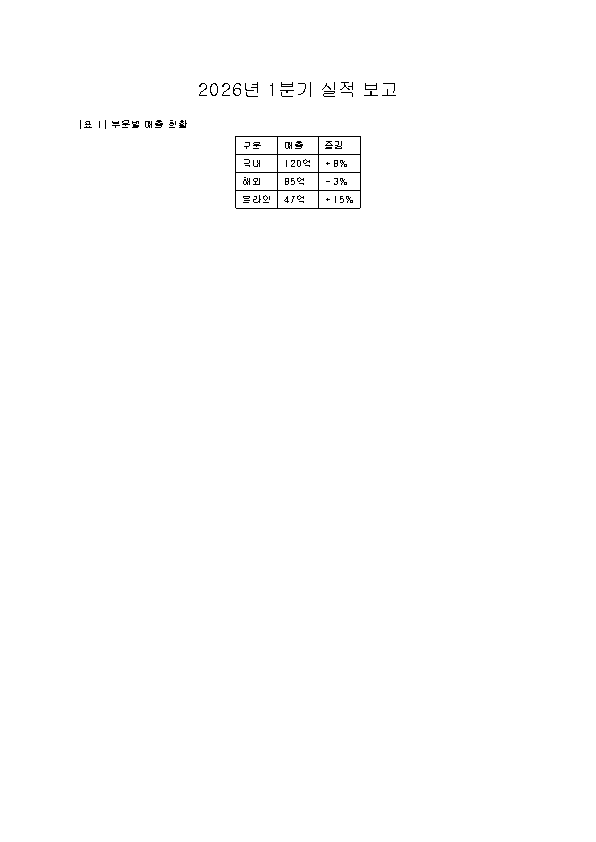

In [22]:
import os

PDF = "content/sample_report.pdf" if os.path.exists("content/sample_report.pdf") \
      else "sample_report.pdf"

# TODO 1: 해상도 (표의 작은 숫자도 또렷하게)
DPI = 72

try:
    import pdfplumber
    with pdfplumber.open(PDF) as pdf:
        # TODO 2: 첫 페이지 → DPI 해상도 이미지 → page_image.png 저장
        pdf.pages[0].to_image(resolution=DPI).save("content/page_image.png")
    print("캡처 방식: pdfplumber")

except ImportError as e:
    # Pillow가 꼬인 환경('_Ink' ImportError) 우회: pypdfium2로 직접 렌더 (그대로 두세요)
    import pypdfium2 as pdfium
    doc = pdfium.PdfDocument(PDF)
    doc[0].render(scale=DPI / 72).to_pil().save("content/page_image.png")
    print(f"캡처 방식: pypdfium2 (pdfplumber 우회 — {e})")

from PIL import Image
# TODO 3: 저장한 이미지 열기
img = Image.open("content/page_image.png")
print(f"✅ PDF 1페이지를 이미지로 캡처: {img.size} px")
img

In [23]:
import os, base64
# OpenAI 키 (Colab 비밀키 또는 환경변수)
try:
    from google.colab import userdata
    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
except Exception:
    pass  # 이미 환경변수에 있으면 그대로 사용

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

with open("content/page_image.png", "rb") as f:
    # TODO 1: 이미지 바이트 → base64 문자열
    img_b64 = base64.b64encode(f.read()).decode()

# TODO 2: 비전 가능 모델 (표 정확도 위해 mini 아닌 gpt-4o, 결과 고정 위해 temperature 0)
vision = ChatOpenAI(model="gpt-4o", temperature=0)

# 프롬프트 핵심: '분석/요약'이 아니라 '전사(OCR)'
ocr_msg = HumanMessage(content=[
    {"type": "text", "text":
     "다음 이미지에 표가 있습니다. OCR 작업입니다: 표의 "
     "각 행과 열에 적힌 글자·숫자를 보이는 그대로 마크다운 "
     "표로 옮기세요. 해석·요약하지 말고 그대로 전사만 하세요."},
    {"type": "image_url",
     # TODO 3: base64 데이터 URL
     "image_url": {"url": f"data:image/png;base64, {img_b64}",
                   "detail": "high"}},
])

# TODO 4: 모델 호출 → 응답 텍스트
vision_table = vision.invoke([ocr_msg]).content

print("─── 비전 복원 결과 ───")
print(vision_table)
if "sorry" in vision_table.lower() or "can't" in vision_table.lower():
    print("\n⚠️ 비전 복원 실패. 셀 재실행 또는 키 권한 확인.")
else:
    print("\n✅ 이미지 표 → 텍스트 복원 성공")

─── 비전 복원 결과 ───
```markdown
| 구분   | 매출  | 증감  |
|-------|-------|-------|
| 국내   | 120억 | +6%   |
| 해외   | 85억  | -3%   |
| 온라인 | 47억  | +15%  |
```

✅ 이미지 표 → 텍스트 복원 성공


4. 셀 11의 비전 결과(`vision_table`)를 셀 5처럼 캡션을 붙여 청크로 만들고,
   셀 7 방식으로 `docstore` / `search_index` 에 추가해 보세요.

In [ ]:
big_table = [
    ["구분", "매출", "증감"],
    ["국내", "120억", "+8%"], ["해외", "85억", "-3%"],
    ["온라인", "47억", "+15%"], ["오프라인", "73억", "-1%"],
    ["B2B", "210억", "+22%"], ["B2C", "88억", "+5%"],
]

caption = "[표] 부문별 매출 현황"

table_chunk = caption + "\n" + table_to_markdown()

> ✏️ 내 생각: